# 3. Dataset-Derived Traces

CarlaGym ships two traces derived from real measurements. Each is a
`step,src,dst,volume` CSV that `TraceTrafficGenerator` replays in place of the synthetic
Poisson traffic.

| Trace | Derived from |
|---|---|
| `data/cs448b_trace.csv` | daily flow counts per (local host, remote ASN) over 92 days; one step = one day |
| `data/pcap_trace.csv` | a packet capture of about 21 minutes, binned into 5-second steps; volume = bytes |

**The raw files are not distributed** (the capture contains real IP addresses, and the
flow-count file has no stated licence). The adapters in
`carla_gym/core/dataset_adapters.py` mapped addresses and ASNs to 16 node ids through a
stable hash, so the traces hold node ids only. This notebook works from the traces alone.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
%matplotlib inline

from carla_gym.core.network import NetworkModel
from carla_gym.core.trace_traffic import TraceTrafficGenerator
from carla_gym.env import CarlaGymEnv
from carla_gym.baselines import policy_queue_proportional, policy_max

plt.rcParams["figure.dpi"] = 100
LOAD = 40.0   # mean offered load per step used below
TRACES = {"cs448b": "data/cs448b_trace.csv", "pcap": "data/pcap_trace.csv"}
traces = {name: pd.read_csv(path) for name, path in TRACES.items()}
NUM_NODES = 16

## What is in each trace

In [2]:
rows = []
for name, df in traces.items():
    per_step = df.groupby("step")["volume"].sum().reindex(range(df["step"].max() + 1), fill_value=0.0)
    pair = df.groupby(["src", "dst"])["volume"].sum().sort_values(ascending=False)
    rows.append({"trace": name, "rows": len(df), "time bins": len(per_step),
                 "bins with traffic": int((per_step > 0).sum()),
                 "source nodes": df["src"].nunique(), "destination nodes": df["dst"].nunique(),
                 "node pairs used": len(pair), "of 240 possible": f"{len(pair) / 240:.0%}",
                 "share of volume on busiest pair": f"{pair.iloc[0] / pair.sum():.0%}",
                 "peak / mean load per bin": round(per_step.max() / per_step.mean(), 1)})
pd.DataFrame(rows).set_index("trace").T

trace,cs448b,pcap
rows,4644,4163
time bins,92,252
bins with traffic,92,246
source nodes,10,16
destination nodes,6,16
node pairs used,60,45
of 240 possible,25%,19%
share of volume on busiest pair,56%,29%
peak / mean load per bin,37.1,8.9


## Load over time

Both traces are bursty: a few time bins carry far more than the average. The dashed line
is the mean. `TraceTrafficGenerator(target_load=...)` rescales the volume so that this
mean equals the load you ask for, so only the *shape* below matters, not the raw units.

cs448b: busiest 10% of bins carry 64% of all volume
pcap: busiest 10% of bins carry 43% of all volume


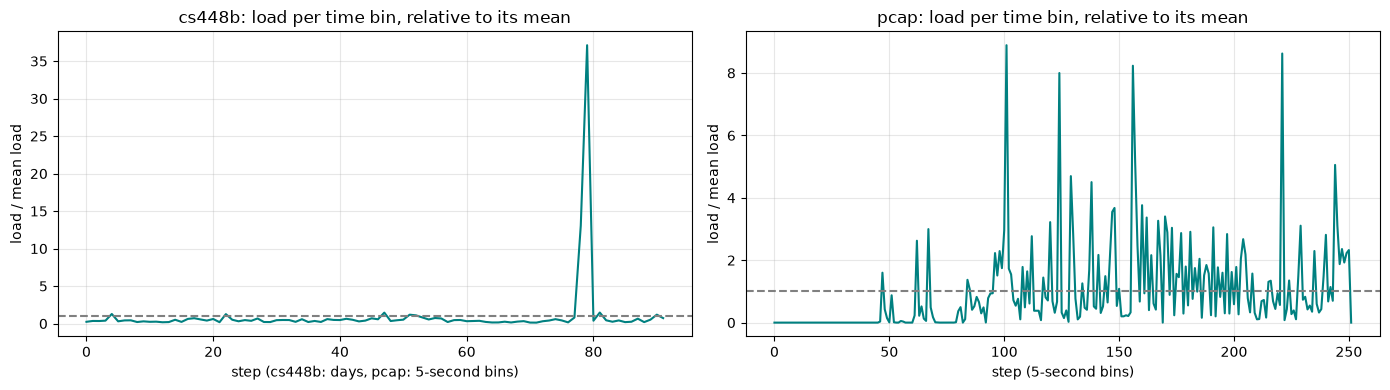

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, df) in zip(axes, traces.items()):
    per_step = df.groupby("step")["volume"].sum().reindex(range(df["step"].max() + 1), fill_value=0.0)
    rel = per_step / per_step.mean()
    ax.plot(rel.index, rel.values, color="teal")
    ax.axhline(1.0, ls="--", color="gray")
    ax.set_title(f"{name}: load per time bin, relative to its mean")
    ax.set_xlabel("step (cs448b: days, pcap: 5-second bins)" if name == "cs448b" else "step (5-second bins)")
    ax.set_ylabel("load / mean load")
    ax.grid(alpha=0.3)
    print(f"{name}: busiest 10% of bins carry {per_step.sort_values(ascending=False).head(max(len(per_step) // 10, 1)).sum() / per_step.sum():.0%} of all volume")
plt.tight_layout(); plt.show()

## Which node pairs carry the load

Real traffic concentrates on few source-destination pairs, unlike the synthetic generator,
which spreads demand over all pairs.

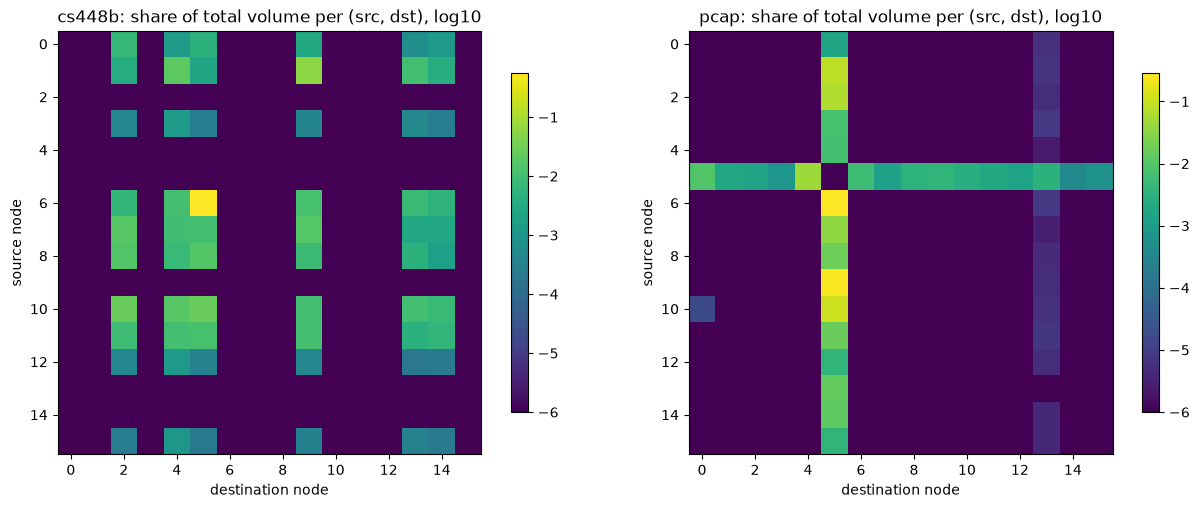

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, df) in zip(axes, traces.items()):
    mat = df.pivot_table(index="src", columns="dst", values="volume", aggfunc="sum", fill_value=0.0)
    mat = mat.reindex(index=range(NUM_NODES), columns=range(NUM_NODES), fill_value=0.0)
    im = ax.imshow(np.log10(mat.values / mat.values.sum() + 1e-6), cmap="viridis")
    ax.set_title(f"{name}: share of total volume per (src, dst), log10")
    ax.set_xlabel("destination node"); ax.set_ylabel("source node")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

## Topology-aware placement

When the traces were built, the busiest address buckets were placed on the best-connected
nodes of the 4x4 grid. A traffic hub on a two-link corner would be a bottleneck that no
bandwidth policy can fix. Below: each node's share of trace volume against its degree, and
the same information drawn on the grid.

cs448b: busiest node is 5 (degree 4, max degree 4), carrying 32% of all endpoint volume
pcap: busiest node is 5 (degree 4, max degree 4), carrying 50% of all endpoint volume


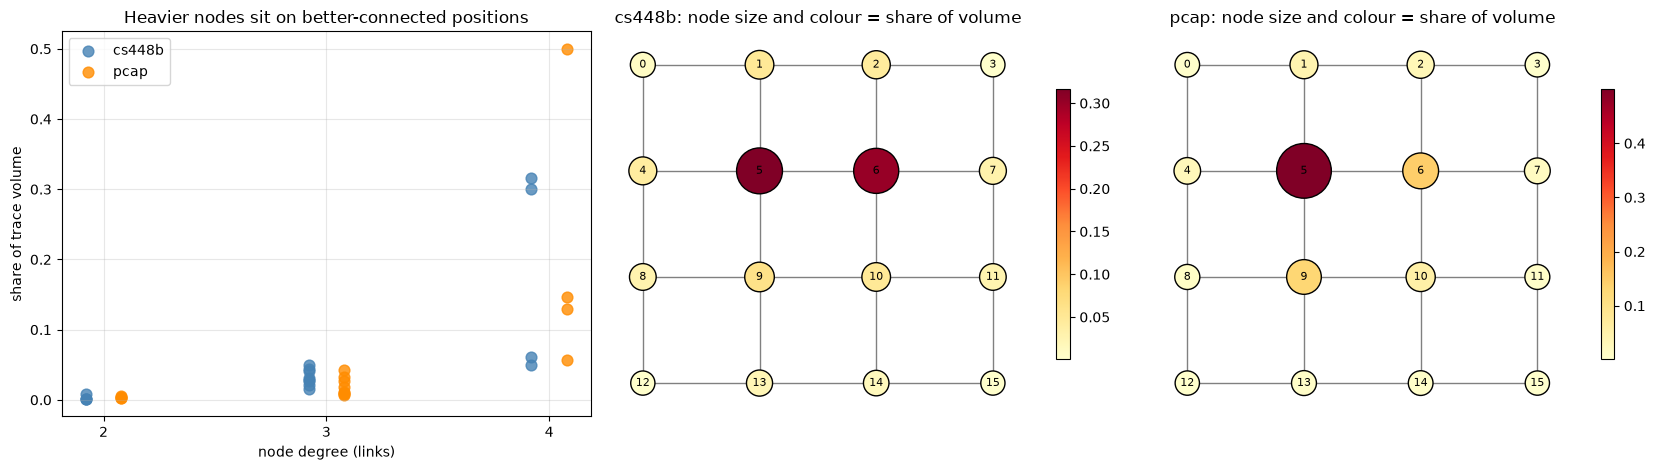

In [5]:
net = NetworkModel(topology="grid", num_nodes=NUM_NODES)
degree = dict(net.graph.degree())
pos = {n: (n % 4, -(n // 4)) for n in net.graph.nodes()}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, color in (("cs448b", "steelblue"), ("pcap", "darkorange")):
    df = traces[name]
    load = df.groupby("src")["volume"].sum().add(df.groupby("dst")["volume"].sum(), fill_value=0.0)
    share = (load / load.sum()).reindex(range(NUM_NODES), fill_value=0.0)
    axes[0].scatter([degree[n] + (0.08 if name == "pcap" else -0.08) for n in share.index], share.values,
                    s=60, color=color, alpha=0.8, label=name)
    busiest = int(share.idxmax())
    print(f"{name}: busiest node is {busiest} (degree {degree[busiest]}, max degree {max(degree.values())}), "
          f"carrying {share.max():.0%} of all endpoint volume")
axes[0].set_xticks([2, 3, 4]); axes[0].set_xlabel("node degree (links)"); axes[0].set_ylabel("share of trace volume")
axes[0].set_title("Heavier nodes sit on better-connected positions"); axes[0].legend(); axes[0].grid(alpha=0.3)
for ax, name in zip(axes[1:], ("cs448b", "pcap")):
    df = traces[name]
    load = df.groupby("src")["volume"].sum().add(df.groupby("dst")["volume"].sum(), fill_value=0.0)
    share = (load / load.sum()).reindex(range(NUM_NODES), fill_value=0.0)
    nx.draw_networkx_edges(net.graph, pos, ax=ax, edge_color="gray")
    nodes = nx.draw_networkx_nodes(net.graph, pos, ax=ax, node_color=share.values, cmap="YlOrRd",
                                   node_size=300 + 2500 * share.values, edgecolors="black")
    nx.draw_networkx_labels(net.graph, pos, ax=ax, font_size=8)
    ax.set_title(f"{name}: node size and colour = share of volume"); ax.axis("off")
    fig.colorbar(nodes, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()

## Both traces through the simulator

Each trace drives `CarlaGymEnv` on the 4x4 grid at a mean load of 40 units per step.
The table reports the fraction of traffic actually delivered and dropped (episode totals),
which for bursty traffic is very different from the average of the per-step reward terms.

In [6]:
from carla_gym.utils.qos import EpisodeQoS

rows, series = [], {}
for name, path in TRACES.items():
    for pol_name, pol in (("queue_proportional", policy_queue_proportional), ("max_bandwidth", policy_max)):
        gen = TraceTrafficGenerator(list(range(NUM_NODES)), path, target_load=LOAD, seed=0)
        env = CarlaGymEnv(topology="grid", num_nodes=NUM_NODES, bandwidth_budget=0.5,
                          max_steps=gen.n_steps, traffic=gen, seed=0)
        obs, _ = env.reset(seed=0)
        qos, offered, backlog, reward = EpisodeQoS(), [], [], []
        for _ in range(gen.n_steps):
            obs, r, _, _, info = env.step(pol(env, obs))
            qos.add(info); offered.append(info["offered_units"]); backlog.append(info["backlog_units"]); reward.append(r)
        s = qos.summary()
        rows.append({"trace": name, "policy": pol_name, "time bins": gen.n_steps,
                     "target load": LOAD, "realised mean load": round(float(np.mean(offered)), 1),
                     "mean reward": round(float(np.mean(reward)), 3),
                     "delivered %": round(100 * s["delivered_fraction"], 1),
                     "dropped %": round(100 * s["dropped_fraction"], 1)})
        if pol_name == "queue_proportional":
            series[name] = (offered, backlog)
pd.DataFrame(rows).set_index(["trace", "policy"])

time bins  target load  realised mean load  \
trace  policy                                                           
cs448b queue_proportional         92         40.0                38.6   
       max_bandwidth              92         40.0                38.6   
pcap   queue_proportional        252         40.0                39.3   
       max_bandwidth             252         40.0                39.3   

                           mean reward  delivered %  dropped %  
trace  policy                                                   
cs448b queue_proportional        0.312         49.5       49.4  
       max_bandwidth             0.382         49.0       50.0  
pcap   queue_proportional        0.209         78.0       20.8  
       max_bandwidth             0.021         62.1       36.1

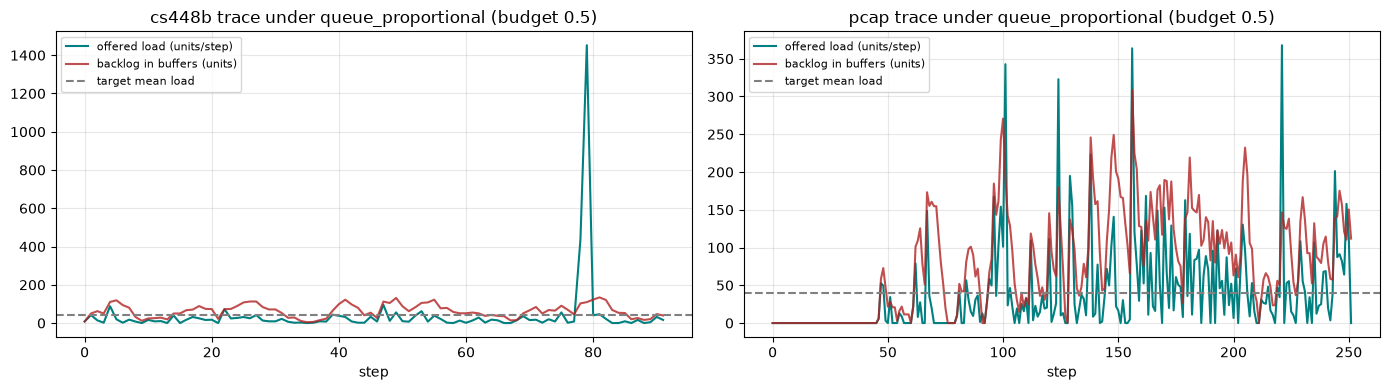

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, (offered, backlog)) in zip(axes, series.items()):
    ax.plot(offered, color="teal", label="offered load (units/step)")
    ax.plot(backlog, color="firebrick", alpha=0.8, label="backlog in buffers (units)")
    ax.axhline(LOAD, ls="--", color="gray", label="target mean load")
    ax.set_title(f"{name} trace under queue_proportional (budget 0.5)")
    ax.set_xlabel("step"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Building a trace from your own data

The adapters are still in the package. Put a raw CSV outside version control
(`data/raw/` is git-ignored) and run:

```
python scripts/prepare_trace.py --in data/raw/my_capture.csv --out data/my_trace.csv --bin-seconds 5
```

Supported inputs: a flow-count table with columns `date, l_ipn, r_asn, f`, or a
packet-capture export with `Timestamp, Source IP, Destination IP, Length` (numeric) or
`Time, Source, Destination, Length` (Wireshark text export). Conversion is deterministic
(stable hashing) and placement is topology-aware.